> **Simulated run**: executed with `SIMULATE = True` (fake SR860s streaming UDP on this PC) to show what to expect. The numbers are made up.

# CryoFree noise survey: choosing the excitation frequency

Uses **dmz_measure** to stream X/Y from the SR860s over ethernet and take our own FFT
(the method from the "SR860 settling time between points" chat):

1. **Survey.** Reference at 100 Hz, τ = 100 µs, sync off, excitation off. All lock-ins
   stream at once (~39 kHz XY). The complex FFT of X + iY is the input spectrum shifted
   by f_ref, so one record gives every channel's noise from **0 to 200 Hz**, at 0.05 Hz
   resolution. Mains, pulse-tube harmonics and stray lines all show up.
2. **Rank.** For every candidate frequency (5 to 95 Hz), predict the noise one data point
   would have with your filter settings. Frequencies near mains fractions (15, 20, 30, 40,
   45 Hz and so on) are avoided.
3. **Check.** Measure the best few candidates at real settings (τ ≈ 1/(30 f), sync on,
   excitation on, a representative gate point). Report the pixel noise of R = V/I, the
   phase and the Allan deviation. Today's 13.2943 Hz is included as the baseline.

**What it touches.** It changes frequency, time constant, slope and sync on the lock-ins,
and during the survey sets SR860_A's sine out to 1 nV. Every setting is snapshotted first
and restored at the end, even after an error or a kernel interrupt. The snapshot is printed
too, so you can restore by hand if the kernel dies.

**Before the first run on the measurement PC**
* Install: `pip install -e "<path to dmz_measure>"`, or leave the `dmz_measure` folder
  one level above this notebook.
* Windows Firewall must let in UDP ports 1865–1880. The connection test below prints the
  exact command if packets don't arrive.
* The lock-ins must be opened as `TCPIP::<ip>::inst0::INSTR` (VXI-11). The SR860 streams
  to the PC that sent `STREAM ON` over VXI-11.

In [1]:
%matplotlib inline
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt

try:
    import dmz_measure as dm
except ImportError:  # not pip-installed: use the package folder next to this notebook
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import dmz_measure as dm
from dmz_measure.plotting import eng
print('dmz_measure', dm.__version__, 'from', pathlib.Path(dm.__file__).parent)

dmz_measure 0.1.0 from C:\Users\declan\Documents\Claude Projects\dmz_measure\dmz_measure


## Settings

In [2]:
SIMULATE = True    # True: fake SR860s on this PC (no fridge needed) to try the notebook out

# Runs are numbered like measureme's sweep (lowest free integer folder), so this can point at
# the sweep data folder (e.g. '../data_03+12') and keep one ID sequence.
BASEDIR = './data_sim' if SIMULATE else './data_dmz'
dm.set_basedir(BASEDIR)

MAINS = 60.0            # Hz
F_NOW = 13.2943         # Hz, the frequency used for the MM03 maps so far (baseline)

## Connect

In [3]:
if SIMULATE:
    from dmz_measure.simulate import fake_cryofree
    fakes = fake_cryofree(seed=1)
    SR860_A, SR860_B, SR860_C = fakes['SR860_A'], fakes['SR860_B'], fakes['SR860_C']
else:
    from qcodes.instrument import Instrument
    from qcodes.instrument_drivers.stanford_research import SR860

    def connect(name, address):
        # re-use the instrument if it is already open in this kernel
        if Instrument.exist(name):
            return Instrument.find_instrument(name)
        return SR860(name, address)

    SR860_A = connect('SR860_A', 'TCPIP::192.168.50.11::inst0::INSTR')
    SR860_B = connect('SR860_B', 'TCPIP::192.168.50.12::inst0::INSTR')
    SR860_C = connect('SR860_C', 'TCPIP::192.168.50.13::inst0::INSTR')
    # SR860_D = connect('SR860_D', 'TCPIP::192.168.50.14::inst0::INSTR')
    # SR860_E = connect('SR860_E', 'TCPIP::192.168.50.15::inst0::INSTR')
    # SR860_F = connect('SR860_F', 'TCPIP::192.168.50.16::inst0::INSTR')

for li in (SR860_A, SR860_B, SR860_C):
    io = dm.LockinIO(li)
    print(f'{io.name}: ref {io.reference_source()}, f = {io.detection_frequency():.4f} Hz, '
          f'tau = {io.time_constant():g} s, sine out = {io.ask_float("SLVL?"):g} V')

SR860_A: ref INT, f = 13.2943 Hz, tau = 0.3 s, sine out = 1 V
SR860_B: ref EXT, f = 13.2943 Hz, tau = 0.3 s, sine out = 1 V
SR860_C: ref EXT, f = 13.2943 Hz, tau = 0.3 s, sine out = 1 V


In [4]:
# Same wiring and gains as the MM03-03 TG4 measurements (MM03_03+12_measure.ipynb).
# gain = what you divide by in s.fp(SR860.X, gain=...); spectra come out input-referred.
measurement_config = {'SR860_A': '9-12', 'SR860_B': '15-14', 'SR860_C': '15-11'}

channels = {
    'SR860_A': dm.Channel(SR860_A, gain=1e6, unit='A'),   # current through the device (1e6 V/A)
    'SR860_B': dm.Channel(SR860_B, gain=100),             # 4-probe voltage (x100 preamp)
    'SR860_C': dm.Channel(SR860_C, gain=100),             # 4-probe voltage (x100 preamp)
}
MASTER = SR860_A     # internal reference + sine out drives the excitation
CURRENT = 'SR860_A'  # channel measuring the current, for R = V/I in step 3

## Connection test

Streams 2 s from SR860_B with τ = 1 ms and sync on, then restores the settings. If
nothing arrives you get a `StreamTimeout` that names the cause, with the firewall command
to run in an administrator PowerShell.

  SR860_B: 19584 samples, 2.0 s at 9765.62 Hz, 153 packets, no drops/flags


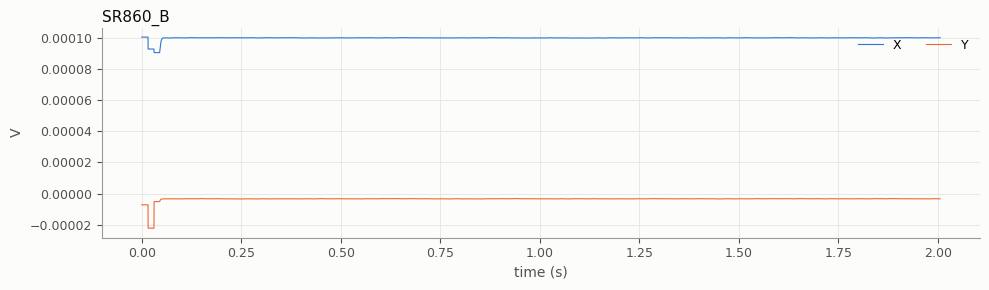

In [5]:
io = dm.LockinIO(SR860_B)
with dm.preserved_settings([io], verbose=False):
    dm.apply_settings(io, tau=1e-3, sync=True)
    time.sleep(0.5)
    test = dm.SR860Stream(io, port=1865).acquire(2.0, rate=10e3)
dm.plotting.plot_stream(test, gain=100, unit='V');

## Step 1: survey (excitation off)

`f_ref = 100 Hz` gives clean coverage of 0–200 Hz: input frequency f appears at offset
f − 100 Hz in the complex FFT. The X/Y sign convention is checked automatically against
the 60/120/180 Hz lines; look for `orientation` below. Longer records give smoother
spectra: resolution × duration ≈ 15 means about 15 averages.

In [6]:
SURVEY_F_REF = 100.0
SURVEY_DURATION = 30 if SIMULATE else 300     # s
RESOLUTION = 0.2 if SIMULATE else 0.05        # Hz

survey = dm.noise_survey(
    channels, master=MASTER, f_ref=SURVEY_F_REF, tau=100e-6, duration=SURVEY_DURATION,
    target_rate=40e3, excitation_off=True, resolution=RESOLUTION, mains=MAINS,
    comment=f'noise survey: f_ref {SURVEY_F_REF:g} Hz, tau 100 us, excitation off',
    measurement_config=measurement_config, basedir=BASEDIR)

Saved lock-in settings (restored automatically when done):
  SR860_A: RSRC=0, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0
  SR860_B: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0
  SR860_C: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0


Streaming 3 lock-in(s) for 30 s at 39062.5 Hz (f_ref = 100.0000 Hz) ...


  SR860_A: 1171840 samples, 30.0 s at 39062.5 Hz, 9155 packets, no drops/flags
  SR860_B: 1172480 samples, 30.0 s at 39062.5 Hz, 9160 packets, no drops/flags
  SR860_C: 1172480 samples, 30.0 s at 39062.5 Hz, 9160 packets, no drops/flags
Lock-in settings restored.


Saved run 0 -> ./data_sim\0


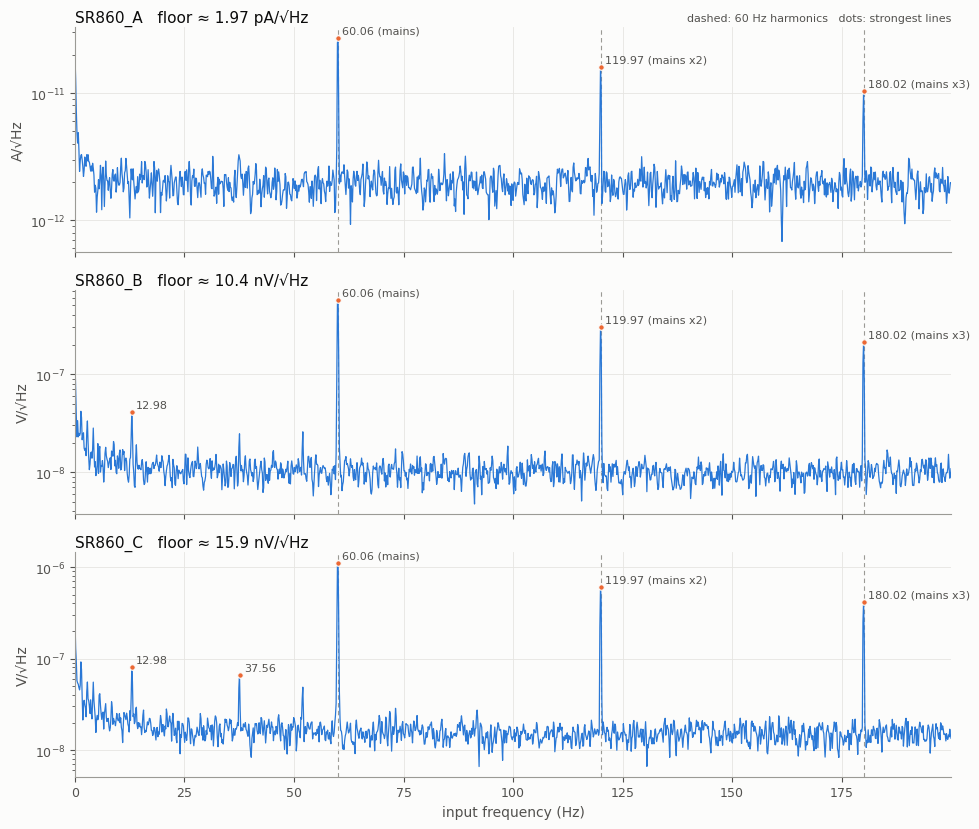

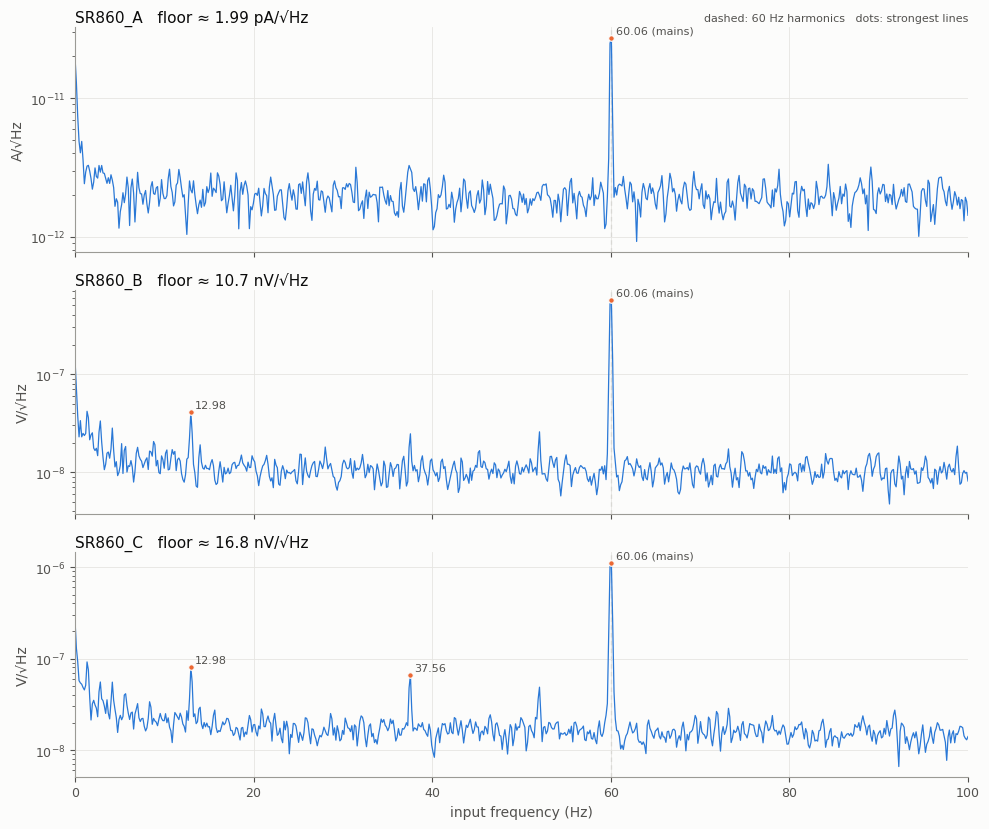

In [7]:
dm.plotting.plot_survey(survey)
plt.show()
dm.plotting.plot_survey(survey, fmax=100, n_labels=10);   # zoom on the candidate range

In [8]:
for name, lines in survey.lines.items():
    s = survey.spectra[name]
    print(f"\n{name}: floor {eng(s.floor(1, 2 * SURVEY_F_REF), s.unit)}/rtHz, "
          f"{s.n_segments} averages, X/Y orientation: {s.meta['orientation']['used']}")
    print(dm.format_table(lines[:15], ['f', 'rms', 'snr_db', 'tag'],
                          headers={'f': 'f (Hz)', 'rms': f'rms ({s.unit})', 'snr_db': 'dB over bg'}))


SR860_A: floor 1.97 pA/rtHz, 7 averages, X/Y orientation: normal
f (Hz)    rms (A)  dB over bg       tag
------  ---------  ----------  --------
 60.06  1.443e-11        21.6     mains
   120  7.826e-12        18.3  mains x2
   180  4.953e-12       14.37  mains x3

SR860_B: floor 10.4 nV/rtHz, 7 averages, X/Y orientation: normal
f (Hz)    rms (V)  dB over bg       tag
------  ---------  ----------  --------
 60.06  3.032e-07       33.75     mains
   120  1.470e-07       28.24  mains x2
   180  1.018e-07       25.47  mains x3
 12.98  1.903e-08        10.7          

SR860_C: floor 15.9 nV/rtHz, 7 averages, X/Y orientation: normal
f (Hz)    rms (V)  dB over bg       tag
------  ---------  ----------  --------
 60.06  5.987e-07       34.25     mains
   120  2.983e-07       31.37  mains x2
   180  2.000e-07       28.42  mains x3
 12.98  3.707e-08       10.78          
 37.56  3.131e-08       11.39          


### Is the noise steady?

The pulse-tube compressor, pumps and building equipment come and go. A spectrogram shows
bursts that a time-averaged spectrum hides. Repeat the survey at another time of day
before committing to a frequency.

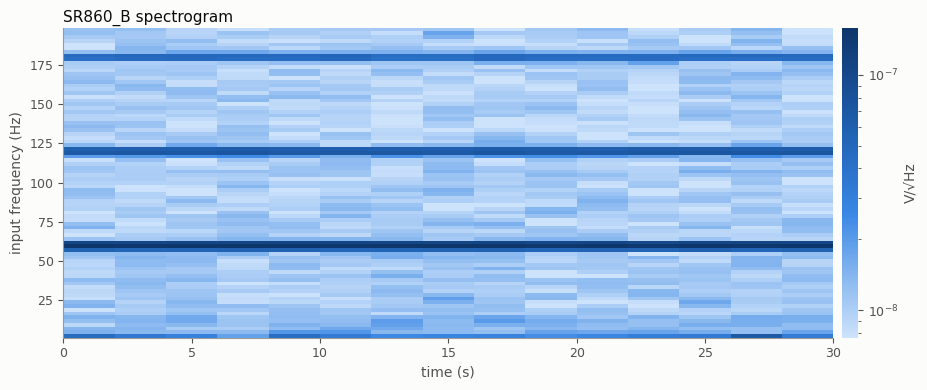

In [9]:
name = 'SR860_B'
d, s = survey.streams[name], survey.spectra[name]
t, f, P = dm.spectrogram(d.z, d.fs, s.f_ref, gain=channels[name].gain,
                         segment=2 if SIMULATE else 10,
                         orientation=s.meta['orientation']['used'])
dm.plotting.plot_spectrogram(t, f, P, name=name, unit=s.unit, fmax=2 * SURVEY_F_REF);

## Step 2: rank frequencies

For each candidate f, the predicted noise of one data point is
σ² = ½ ∫ S(f') (|H(f' − f)|² + |H(f' + f)|²) df′, with H the filter that makes one data
point. Each channel is normalised to its own median, and the channels are combined with a
geometric mean, because one reference frequency has to work for all of them.

* `FILTER_NOW`: today's stepped maps, one reading at τ = 300 ms, 24 dB/oct.
* `FILTER_STREAM`: the streaming recipe, τ ≈ 1 ms + sync, averaged over a 0.3 s pixel.

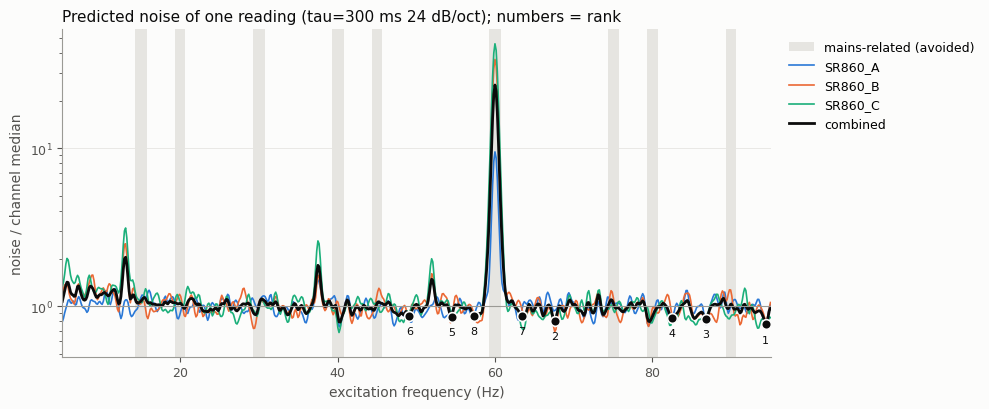

    f   score  SR860_A_noise  SR860_B_noise  SR860_C_noise  nearest_line_f  nearest_line_tag
-----  ------  -------------  -------------  -------------  --------------  ----------------
94.41  0.7648      7.703e-13      4.475e-09      6.467e-09             120          mains x2
67.58  0.8055      9.608e-13      3.826e-09      7.086e-09           60.06             mains
86.81  0.8312      7.849e-13      4.788e-09      7.614e-09           60.06             mains
82.49  0.8416      8.817e-13      4.807e-09      7.010e-09           60.06             mains
54.47  0.8571      9.053e-13      4.404e-09      7.871e-09           60.06             mains
49.11  0.8662      8.459e-13      4.879e-09      7.847e-09           60.06             mains
63.41  0.8683      9.709e-13      5.313e-09      6.324e-09           60.06             mains
 57.3  0.8687      8.800e-13      4.926e-09      7.535e-09           60.06             mains

Today's 13.2943 Hz with the same filter:
  SR860_A: 1.1 pA now vs 770

In [10]:
FILTER_NOW = dm.MeasurementFilter(tau=0.3, slope_db=24)
FILTER_STREAM = dm.MeasurementFilter(tau=1e-3, slope_db=24, sync=True, dwell=0.3)

rank = survey.rank(FILTER_NOW, fmin=5, fmax=95, n_best=8, mains=MAINS)
dm.plotting.plot_ranking(rank)
plt.show()
cols = ['f', 'score'] + [f'{n}_noise' for n in channels] + ['nearest_line_f', 'nearest_line_tag']
print(dm.format_table(rank.best, cols))

print(f'\nToday\'s {F_NOW} Hz with the same filter:')
for name, s in survey.spectra.items():
    now = dm.predicted_noise(s, [F_NOW], FILTER_NOW)[0]
    best = rank.best[0][f'{name}_noise']
    print(f'  {name}: {eng(now, s.unit)} now vs {eng(best, s.unit)} at {rank.best[0]["f"]:.2f} Hz '
          f'({now / best:.2f}x)')

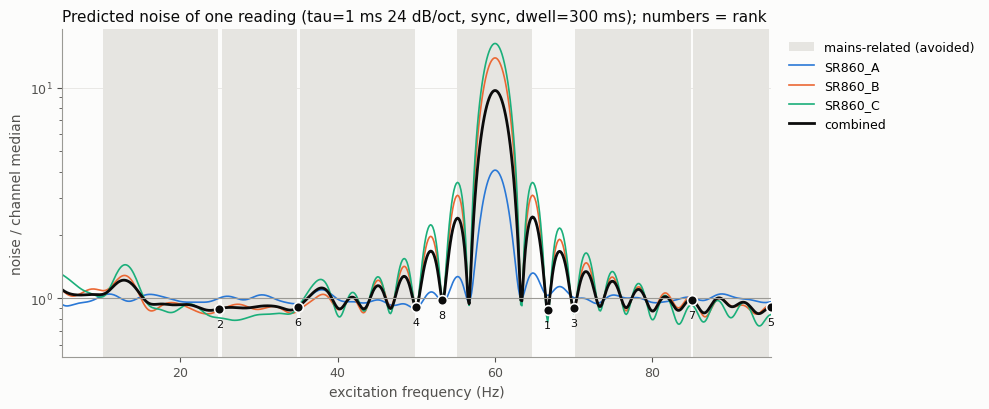

    f   score  SR860_A_noise  SR860_B_noise  SR860_C_noise  nearest_line_f  nearest_line_tag
-----  ------  -------------  -------------  -------------  --------------  ----------------
66.69  0.8817      2.685e-12      1.330e-08      2.021e-08           60.06             mains
24.97  0.8938      2.608e-12      1.362e-08      2.118e-08           12.98                  
69.97  0.9054      2.623e-12      1.342e-08      2.220e-08           60.06             mains
   50  0.9071      2.331e-12      1.438e-08      2.345e-08           60.06             mains
   95  0.9077      2.503e-12      1.437e-08      2.190e-08             120          mains x2
34.95   0.909      2.458e-12      1.357e-08      2.373e-08           37.56                  
85.02   0.984      2.619e-12      1.575e-08      2.434e-08           60.06             mains
53.28  0.9845      2.502e-12      1.554e-08      2.586e-08           60.06             mains


In [11]:
rank_stream = survey.rank(FILTER_STREAM, fmin=5, fmax=95, n_best=8, mains=MAINS)
dm.plotting.plot_ranking(rank_stream)
plt.show()
print(dm.format_table(rank_stream.best, cols))

## Step 3: check the candidates at real settings (excitation ON)

The ranking only covers **additive** noise (pickup, preamp, vibration). This step measures
the real thing: put the device at a representative gate point with the excitation on, then
measure each candidate for a few minutes.
* τ = largest SR860 value ≤ 1/(30 f), sync on, streamed at ~10/τ.
* `R_rel_noise`: scatter of 0.3 s pixel averages of Re(V/I), relative to R. This is the
  number to compare.
* `R_phase_deg`: phase of V/I. Below ~5° is fine and above ~15° is suspect. A higher f
  makes cable capacitance worse.
* The Allan deviation should fall like 1/√τ. Where it flattens or rises, drift takes over.

In [12]:
# Set the gate point first, e.g. in the measurement notebook: s.ramp(Kbg2.volt, 1); s.ramp(Ktg2.volt, 1)
CANDIDATES = [b['f'] for b in rank.best[:4]] + [F_NOW]

check = dm.candidate_check(
    channels, master=MASTER, frequencies=CANDIDATES, duration=10 if SIMULATE else 120,
    dwell=0.3, tau=None, sync=True, current=CURRENT,
    comment='frequency check at a representative gate point',
    measurement_config=measurement_config, basedir=BASEDIR)

Saved lock-in settings (restored automatically when done):
  SR860_A: RSRC=0, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0
  SR860_B: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0
  SR860_C: RSRC=1, OFLT=11, OFSL=3, SYNC=0, ADVFILT=1, HARM=1, FREQ=13.2943, SLVL=1.0



94.4070 Hz: tau = 300 us, sync on, stream 19531.2 Hz, 10 s


  SR860_A: 195840 samples, 10.0 s at 19531.2 Hz, 1530 packets, no drops/flags
  SR860_B: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags
  SR860_C: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags



67.5849 Hz: tau = 300 us, sync on, stream 19531.2 Hz, 10 s


  SR860_A: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags
  SR860_B: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags
  SR860_C: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags



86.8074 Hz: tau = 300 us, sync on, stream 19531.2 Hz, 10 s


... (2 outputs left out)

  SR860_A: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags
  SR860_B: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags
  SR860_C: 195584 samples, 10.0 s at 19531.2 Hz, 1528 packets, no drops/flags



13.2943 Hz: tau = 1 ms, sync on, stream 9765.62 Hz, 10 s


  SR860_A: 97792 samples, 10.0 s at 9765.62 Hz, 764 packets, no drops/flags
  SR860_B: 97792 samples, 10.0 s at 9765.62 Hz, 764 packets, no drops/flags
  SR860_C: 97920 samples, 10.0 s at 9765.62 Hz, 765 packets, no drops/flags
Lock-in settings restored.


Saved run 1 -> ./data_sim\1


    f        tau  SR860_B_R  SR860_B_R_rel_noise  SR860_B_R_phase_deg  SR860_C_R  SR860_C_R_rel_noise  SR860_C_R_phase_deg
-----  ---------  ---------  -------------------  -------------------  ---------  -------------------  -------------------
94.41  3.000e-04      947.2            1.506e-04               -13.28      525.2            4.302e-04               -20.68
67.58  3.000e-04      972.2            2.353e-04               -9.591      559.2            8.807e-04               -15.13
86.81  3.000e-04        955            1.365e-04               -12.24      535.4            3.730e-04               -19.14
82.49  3.000e-04      959.2            1.567e-04               -11.65        541            3.921e-04               -18.26
13.29      0.001      998.9            2.122e-04               -1.902      598.3            6.368e-04               -3.051
flags: none


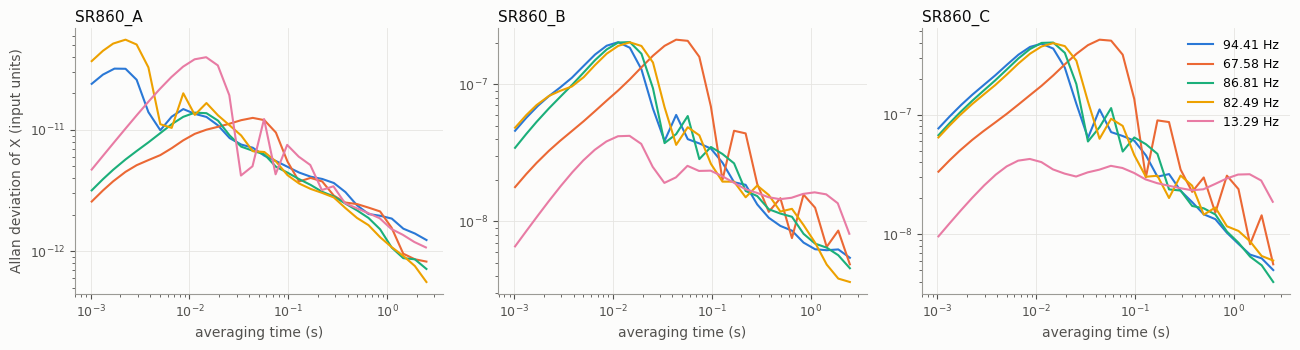

In [13]:
volts = [n for n in channels if n != CURRENT]
cols = ['f', 'tau'] + sum([[f'{n}_R', f'{n}_R_rel_noise', f'{n}_R_phase_deg'] for n in volts], [])
print(dm.format_table(check.rows, cols))
flags = {r['f']: {n: r[f'{n}_flags'] for n in channels if r.get(f'{n}_flags')} for r in check.rows}
print('flags:', {f: v for f, v in flags.items() if v} or 'none')
dm.plotting.plot_check(check);

## Choosing and using the frequency

Pick the candidate with the lowest `R_rel_noise` whose phase stays small, then set it on
the master: `SR860_A.frequency(f_best)`. The other lock-ins follow on external reference.
Re-zero any phase offsets at the new frequency. Repeat the survey now and then (compressor
service, new wiring) and keep the runs, which are saved with spectra, lines, time series
and plots:

In [14]:
run = dm.load_run(survey.run_id, BASEDIR)
print(run.dir)
print(run.metadata['type'], '| columns:', run.metadata['columns'])

./data_sim\0
noise_survey | columns: ['f_Hz', 'SR860_A_asd_A_per_rtHz', 'SR860_B_asd_V_per_rtHz', 'SR860_C_asd_V_per_rtHz']
